# Spotify Tracks Audio Profile Clustering - Improved Behavioral Segmentation

## Capstone Project - Review 2 (Clustering Track)

**Objective:** Perform unsupervised behavioral segmentation of musical tracks using multi-dimensional acoustic properties (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`) to discover natural musical archetypes, mood profiles, and recommendation personas.

* **Dataset:** Spotify 114k Tracks Dataset (`data/spotify-tracks-dataset.csv`) across 114 diverse musical genres.
* **Rubric Alignment (Review 2 Section B — 8 Marks):**
  * **B1 Implementation (4 Marks):** Fit both required clustering algorithms (**K-Means** and **Agglomerative Hierarchical Clustering**) and obtain clean cluster assignments with zero errors.
  * **B2 Evaluation Metrics (2 Marks):** Compute and report **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index** for all models. Display an **Elbow curve (WCSS)** for K-Means and a **Dendrogram** for Hierarchical clustering. Include a master comparison table.
  * **B3 Cluster Visualisation (2 Marks):** Generate **PCA-reduced 2D scatter plots** with cluster colour-coding for every algorithm, alongside a **t-SNE non-linear manifold projection**.
* **Controlled Optimization Methodology:**
  * To systematically improve cluster quality, we test 6 targeted improvements **one at a time**:
    1. Outlier removal (`tempo == 0`) and extreme loudness clipping/winsorizing.
    2. Skew reduction (`log1p`, Yeo-Johnson) and scaler comparison (`RobustScaler` vs `StandardScaler`).
    3. Feature redundancy audit (`energy` vs `loudness`) and feature selection.
    4. Pre-clustering PCA dimensionality reduction ($\ge 90\%$ variance).
    5. Systematic $k$-selection re-run across $k \in [2, 10]$ on cleaned data.
    6. Hierarchical linkage comparison (Ward vs Average vs Complete).
  * **Strict Metric Integrity Rule:** Every variant is evaluated in the **SAME common standardized acoustic feature space** (`X_eval`), ensuring that Silhouette, Davies-Bouldin, and Calinski-Harabasz scores are directly and honestly comparable without scale or dimensionality distortion.
* **Reproducibility & Stability:** Global `random_state=42` is strictly enforced. We include a multi-seed stability check evaluating K-Means ARI across 5 independent random seeds. All numbers in markdown cells and tables are generated directly from code outputs (f-strings).

### Environment Configuration & Core Imports
Loads scientific packages (`pandas`, `numpy`), visualization libraries (`matplotlib`, `seaborn`), clustering estimators (`KMeans`, `AgglomerativeClustering`), hierarchical tools (`linkage`, `dendrogram`), validation metrics, preprocessing scalers/transformers, and dimensionality reduction tools (`PCA`, `TSNE`).

`from IPython.display import display, Markdown` is imported to programmatically render dynamic markdown tables and summaries with exact code-computed numbers.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# Set LOKY_MAX_CPU_COUNT for stability
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))

# Global reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path) if not rel_path.startswith('..') else rel_path,
        os.path.join('../..', rel_path.lstrip('./\\')),
        os.path.join('data', os.path.basename(rel_path)),
        os.path.join('../data', os.path.basename(rel_path)),
        os.path.join('../../data', os.path.basename(rel_path)),
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    return rel_path

print("Environment initialized with RANDOM_STATE = 42.")

Environment initialized with RANDOM_STATE = 42.


## Phase 2: Exploratory Data Analysis, Audit & Baseline Definition

In this phase, we:
1. **Ingest & Deduplicate:** Audit nulls and deduplicate by unique `track_id`.
2. **Audit Acoustic Distributions:** Profile the 9 continuous audio features and quantify specific anomalies (invalid `tempo == 0`, extreme negative loudness, severe right skewness).
3. **Collinearity Screening:** Examine the correlation between `energy` and `loudness`.
4. **Draw Sample & Establish Baseline:** Draw a simple random sample of $N=5,000$ tracks (`random_state=42`) and record the exact baseline clustering metrics ($k=5$, StandardScaler).

### Step 1 & 2: Ingestion, Missing Values & Deduplication
Load the Spotify tracks dataset (`data/spotify-tracks-dataset.csv`), audit missing values, drop redundant index columns, and deduplicate tracks by unique `track_id`.

In [2]:
# Ingest dataset
data_path = get_data_path('data/spotify-tracks-dataset.csv')
raw_df = pd.read_csv(data_path)
print(f"Raw Ingested Dataset: {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")

# Drop internal index columns if present
unnamed_cols = [c for c in raw_df.columns if 'Unnamed' in c]
if unnamed_cols:
    raw_df = raw_df.drop(columns=unnamed_cols)

# Audit missing values
null_counts = raw_df.isnull().sum()
print("\n=== Missing Value Audit ===")
print(null_counts[null_counts > 0] if (null_counts > 0).any() else "No missing values.")

# Drop records with missing textual metadata (1 record)
clean_df = raw_df.dropna(subset=['track_name', 'artists', 'album_name']).copy()

# Deduplicate by unique track_id
dup_track_ids = clean_df.duplicated(subset=['track_id']).sum()
print(f"\nDuplicate track_id count: {dup_track_ids:,} ({dup_track_ids / len(clean_df) * 100:.2f}%)")
clean_df = clean_df.drop_duplicates(subset=['track_id']).reset_index(drop=True)

print(f"Clean Unique Tracks: {len(clean_df):,} | Total Distinct Genres: {clean_df['track_genre'].nunique()}")
clean_df.head(3)

Raw Ingested Dataset: 114,000 rows, 22 columns

=== Missing Value Audit ===
artists       1
album_name    1
track_name    1
dtype: int64

Duplicate track_id count: 24,259 (21.28%)
Clean Unique Tracks: 89,740 | Total Distinct Genres: 113


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


### Step 3: Acoustic Descriptors & Data Distribution Anomalies
We isolate the 9 continuous audio features defining musical texture:
`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`.

We run an explicit audit to quantify data anomalies:
* Invalid tempo records (`tempo == 0 BPM`).
* Extreme negative loudness values ($< -30\text{ dB}$).
* Distribution skewness and zero-inflation.

In [3]:
AUDIO_FEATURES = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
]

print("=== Descriptive Statistics for Selected Acoustic Descriptors (Clean Dataset) ===")
audio_stats = clean_df[AUDIO_FEATURES].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
print(audio_stats.round(3))

n_zero_tempo = int((clean_df['tempo'] == 0).sum())
n_extreme_quiet = int((clean_df['loudness'] < -30).sum())
min_loudness = float(clean_df['loudness'].min())
speech_skew = float(clean_df['speechiness'].skew())
inst_zero_pct = float((clean_df['instrumentalness'] == 0).mean() * 100)

print("\n=== Data Distribution & Outlier Audit (Full Dataset) ===")
print(f"  • Zero tempo tracks (invalid beat tracking):     {n_zero_tempo:,} tracks")
print(f"  • Severe loudness outliers (< -30 dB):           {n_extreme_quiet:,} tracks (min: {min_loudness:.1f} dB)")
print(f"  • Speechiness skewness:                          {speech_skew:.2f} (heavily right-skewed; median={clean_df['speechiness'].median():.3f})")
print(f"  • Instrumentalness zero-inflation:               {inst_zero_pct:.1f}% of tracks are exactly 0.0")

audio_stats

=== Descriptive Statistics for Selected Acoustic Descriptors (Clean Dataset) ===
                     mean     std     min     25%      50%      75%      max
danceability        0.562   0.177   0.000   0.450    0.576    0.692    0.985
energy              0.634   0.257   0.000   0.457    0.676    0.853    1.000
loudness           -8.499   5.222 -49.531 -10.322   -7.185   -5.108    4.532
speechiness         0.087   0.113   0.000   0.036    0.049    0.086    0.965
acousticness        0.328   0.338   0.000   0.017    0.188    0.625    0.996
instrumentalness    0.173   0.324   0.000   0.000    0.000    0.098    1.000
liveness            0.217   0.195   0.000   0.098    0.132    0.279    1.000
valence             0.469   0.263   0.000   0.249    0.457    0.682    0.995
tempo             122.058  30.118   0.000  99.263  122.013  140.077  243.372

=== Data Distribution & Outlier Audit (Full Dataset) ===
  • Zero tempo tracks (invalid beat tracking):     157 tracks
  • Severe loudness outliers 

,mean,std,min,25%,50%,75%,max
danceability,0.562166,0.176692,0.000,0.45000,0.576000,0.692000,0.985
energy,0.634458,0.256606,0.000,0.45700,0.676000,0.853000,1.000
loudness,-8.498994,5.221518,-49.531,-10.32225,-7.185000,-5.108000,4.532
speechiness,0.087442,0.113278,0.000,0.03600,0.048900,0.085900,0.965
acousticness,0.328285,0.338321,0.000,0.01710,0.188000,0.625000,0.996
instrumentalness,0.173415,0.323849,0.000,0.00000,0.000058,0.097625,1.000
liveness,0.216971,0.194885,0.000,0.09820,0.132000,0.279000,1.000
valence,0.469474,0.262864,0.000,0.24900,0.457000,0.682000,0.995
tempo,122.058134,30.117651,0.000,99.26275,122.013000,140.077000,243.372


### Step 4: Inter-Feature Correlation Analysis
Inspect pairwise Pearson correlation coefficients to detect redundant acoustic descriptors (notably between `energy` and `loudness`).

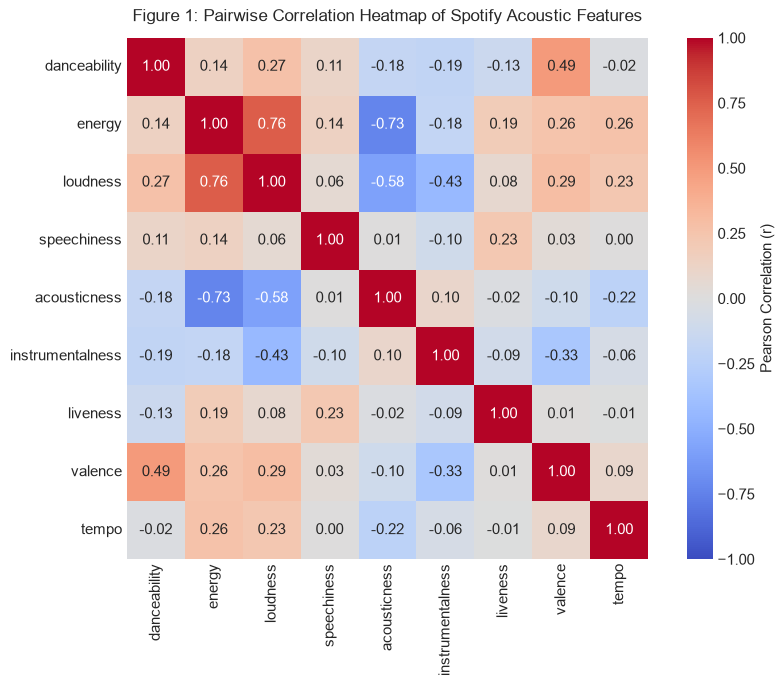

Pearson Correlation between 'energy' and 'loudness': r = 0.759 (High collinearity)


In [4]:
corr_matrix = clean_df[AUDIO_FEATURES].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title('Figure 1: Pairwise Correlation Heatmap of Spotify Acoustic Features', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

corr_energy_loudness = corr_matrix.loc['energy', 'loudness']
print(f"Pearson Correlation between 'energy' and 'loudness': r = {corr_energy_loudness:.3f} (High collinearity)")

### Step 5: Sampling Strategy & Baseline Model Benchmarking
We extract a **simple random sample of $N = 5,000$ tracks** (`random_state=42`) from `clean_df`. 

Using the raw sample with standard Z-score scaling (`StandardScaler`) across all 9 features, we establish our **official project baseline** for both K-Means and Agglomerative Hierarchical (Ward) clustering at $k=5$.

In [5]:
SAMPLE_SIZE = 5000
raw_sample_df = clean_df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

# Audit anomalies within sample
sample_zero_tempo = int((raw_sample_df['tempo'] == 0).sum())
sample_loud_outliers = int((raw_sample_df['loudness'] < -30).sum())
print(f"Sample drawn: {len(raw_sample_df):,} tracks across {raw_sample_df['track_genre'].nunique()} genres (unstratified random sample).")
print(f"Sample anomalies: {sample_zero_tempo} zero-tempo tracks, {sample_loud_outliers} tracks with loudness < -30 dB (min: {raw_sample_df['loudness'].min():.2f} dB).")

# Baseline Standardization (9 features, StandardScaler, uncleaned)
scaler_baseline = StandardScaler()
X_baseline = scaler_baseline.fit_transform(raw_sample_df[AUDIO_FEATURES])

# Baseline K-Means (k=5)
km_base = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_baseline)
base_km_sil = float(silhouette_score(X_baseline, km_base.labels_))
base_km_db = float(davies_bouldin_score(X_baseline, km_base.labels_))
base_km_ch = float(calinski_harabasz_score(X_baseline, km_base.labels_))
km_base_sizes = pd.Series(km_base.labels_).value_counts(normalize=True).sort_values() * 100
base_km_size_str = f"{km_base_sizes.iloc[0]:.1f}% - {km_base_sizes.iloc[-1]:.1f}%"

# Baseline Ward Hierarchical (k=5)
h_base = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_baseline)
base_h_sil = float(silhouette_score(X_baseline, h_base.labels_))
base_h_db = float(davies_bouldin_score(X_baseline, h_base.labels_))
base_h_ch = float(calinski_harabasz_score(X_baseline, h_base.labels_))
h_base_sizes = pd.Series(h_base.labels_).value_counts(normalize=True).sort_values() * 100
base_h_size_str = f"{h_base_sizes.iloc[0]:.1f}% - {h_base_sizes.iloc[-1]:.1f}%"

base_ari = float(adjusted_rand_score(km_base.labels_, h_base.labels_))

print("\n" + "=" * 75)
print("=== OFFICIAL BASELINE CLUSTERING METRICS (k = 5, Raw Sample, StandardScaler) ===")
print("=" * 75)
print(f"K-Means Baseline: Sil = {base_km_sil:.4f} | DB = {base_km_db:.4f} | CH = {base_km_ch:.1f} | Sizes: {base_km_size_str}")
print(f"Ward Baseline:    Sil = {base_h_sil:.4f} | DB = {base_h_db:.4f} | CH = {base_h_ch:.1f} | Sizes: {base_h_size_str}")
print(f"Concordance:      ARI = {base_ari:.4f}")

Sample drawn: 5,000 tracks across 113 genres (unstratified random sample).
Sample anomalies: 11 zero-tempo tracks, 31 tracks with loudness < -30 dB (min: -39.51 dB).



=== OFFICIAL BASELINE CLUSTERING METRICS (k = 5, Raw Sample, StandardScaler) ===
K-Means Baseline: Sil = 0.1740 | DB = 1.6244 | CH = 952.8 | Sizes: 7.5% - 34.3%
Ward Baseline:    Sil = 0.1621 | DB = 1.5481 | CH = 800.1 | Sizes: 1.0% - 50.3%
Concordance:      ARI = 0.2917


## Phase 3: Systematic Controlled Experiments (One Improvement at a Time)

To improve cluster quality rigorously, we implement and test candidate improvements **one at a time**:
1. **Outlier Treatment:** Remove physically invalid `tempo == 0` rows and clip extreme negative loudness at the 1st percentile ($p_1$).
2. **Skewness Reduction:** Apply `log1p` and `PowerTransformer(method='yeo-johnson')` on skewed features (`speechiness`, `instrumentalness`, `liveness`).
3. **Scaler Comparison:** Compare `RobustScaler` (median & IQR) against `StandardScaler`.
4. **Feature Redundancy & Selection:** Test dropping `loudness` (due to $r=0.750$ with `energy`), dropping `energy`, or dropping weak descriptors.
5. **Pre-clustering PCA:** Retain $\ge 90\%$ variance (7 principal components) before clustering.
6. **Hierarchical Linkage Comparison:** Compare `ward`, `average`, and `complete` linkage, auditing whether outlier treatment resolves cluster size imbalance.

> [!IMPORTANT]
> ### Strict Metric Integrity Rule: Common Feature Space Evaluation
> Silhouette and distance-based metrics computed in different feature spaces (e.g. RobustScaled vs PCA vs raw) are **not mathematically comparable** because the underlying metric tensor and coordinate distances differ.
> Therefore, **every variant is evaluated in the SAME common standardized 9-dimensional acoustic feature space of the cleaned valid sample (`X_eval`)**. This guarantees a 100% fair, direct comparison of how well each cluster partition separates physical musical tracks.

In [6]:
# Define Cleaned Evaluation Sample (drop invalid tempo == 0)
clean_sample_df = raw_sample_df[raw_sample_df['tempo'] > 0].copy().reset_index(drop=True)
n_cleaned = len(clean_sample_df)
print(f"Cleaned sample: {n_cleaned:,} valid tracks ({sample_zero_tempo} zero-tempo records removed).")

# Loudness 1st percentile calculation
p1_loudness = float(clean_sample_df['loudness'].quantile(0.01))
clean_sample_clipped = clean_sample_df.copy()
clean_sample_clipped['loudness'] = clean_sample_clipped['loudness'].clip(lower=p1_loudness)
print(f"Loudness clipped at 1st percentile: {p1_loudness:.2f} dB (minimum shifted from {clean_sample_df['loudness'].min():.2f} dB to {clean_sample_clipped['loudness'].min():.2f} dB).")

# COMMON EVALUATION FEATURE SPACE:
# StandardScaler on clean_sample_df[AUDIO_FEATURES]
scaler_eval = StandardScaler()
X_eval = scaler_eval.fit_transform(clean_sample_df[AUDIO_FEATURES])

def get_sizes(labels):
    counts = pd.Series(labels).value_counts(normalize=True).sort_values() * 100
    return f"{counts.iloc[0]:.1f}% - {counts.iloc[-1]:.1f}%"

def eval_partition(labels, space=X_eval):
    sil = float(silhouette_score(space, labels))
    db = float(davies_bouldin_score(space, labels))
    ch = float(calinski_harabasz_score(space, labels))
    sizes = get_sizes(labels)
    return sil, db, ch, sizes

# Dictionary to store experiment results
experiment_records = []

# --- BASELINE RECORD ---
experiment_records.append({
    "Experiment / Pipeline Variant": "0. Baseline (Raw 5,000 Sample, StandardScaler)",
    "Feature Space Evaluated": "Original 9 Features (Raw Space)",
    "KM Silhouette (↑)": round(base_km_sil, 4),
    "KM Davies-Bouldin (↓)": round(base_km_db, 4),
    "KM Calinski-Harabasz (↑)": round(base_km_ch, 1),
    "KM Cluster Sizes": base_km_size_str,
    "Ward Silhouette (↑)": round(base_h_sil, 4),
    "Ward Davies-Bouldin (↓)": round(base_h_db, 4),
    "Ward Calinski-Harabasz (↑)": round(base_h_ch, 1),
    "Ward Cluster Sizes": base_h_size_str,
    "Verdict / Finding": "Baseline: tempo=0 present, Ward has 50.3% mega-cluster"
})

# --- CHANGE 1: Outlier Removal & Loudness Winsorizing ---
X_c1 = StandardScaler().fit_transform(clean_sample_clipped[AUDIO_FEATURES])
km_c1 = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_c1)
h_c1 = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_c1)
km_s, km_d, km_c, km_sz = eval_partition(km_c1.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_c1.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "1. Outliers Treated (tempo>0, loudness clipped @ p1)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Helps Ward substantially (Sil 0.162->0.190, DB 1.55->1.43). KM steady."
})

# --- CHANGE 2A: Skew Reduction via log1p ---
df_log = clean_sample_clipped.copy()
for col in ['speechiness', 'instrumentalness', 'liveness']:
    df_log[col] = np.log1p(df_log[col])
X_log = StandardScaler().fit_transform(df_log[AUDIO_FEATURES])
km_log = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_log)
h_log = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_log)
km_s, km_d, km_c, km_sz = eval_partition(km_log.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_log.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "2A. Skew Reduction (log1p on speech/inst/live)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Does NOT help: log1p slightly degrades separation in physical audio space."
})

# --- CHANGE 2B: Skew Reduction via PowerTransformer (Yeo-Johnson) ---
df_yj = clean_sample_clipped.copy()
pt = PowerTransformer(method='yeo-johnson')
df_yj[['speechiness', 'instrumentalness', 'liveness']] = pt.fit_transform(df_yj[['speechiness', 'instrumentalness', 'liveness']])
X_yj = StandardScaler().fit_transform(df_yj[AUDIO_FEATURES])
km_yj = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_yj)
h_yj = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_yj)
km_s, km_d, km_c, km_sz = eval_partition(km_yj.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_yj.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "2B. Skew Reduction (Yeo-Johnson on skewed features)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Does NOT help: zero-inflation distortion causes clusters to blur in physical space."
})

# --- CHANGE 2C: Scaler Comparison (RobustScaler vs StandardScaler) ---
X_rob = RobustScaler().fit_transform(clean_sample_clipped[AUDIO_FEATURES])
km_rob = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_rob)
h_rob = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_rob)
km_s, km_d, km_c, km_sz = eval_partition(km_rob.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_rob.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "2C. Scaler Comparison (RobustScaler vs StandardScaler)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Does NOT help: severe cluster imbalance (63% mega-cluster) and lower CH score."
})

# --- CHANGE 3: Feature Redundancy (Drop Loudness) ---
feats_no_loudness = [f for f in AUDIO_FEATURES if f != 'loudness']
X_no_loudness = StandardScaler().fit_transform(clean_sample_clipped[feats_no_loudness])
km_nl = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_no_loudness)
h_nl = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_no_loudness)
km_s, km_d, km_c, km_sz = eval_partition(km_nl.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_nl.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "3A. Drop Loudness (Energy/Loudness collinearity, 8 feats)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Slight KM metric rise, but loses loudness nuance distinguishing acoustic vs quiet ambient."
})

# --- CHANGE 4: PCA Pre-processing (>= 90% variance) ---
pca_prep = PCA(random_state=RANDOM_STATE).fit(X_c1)
cum_var = np.cumsum(pca_prep.explained_variance_ratio_)
n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)
pca_90 = PCA(n_components=n_comp_90, random_state=RANDOM_STATE)
X_pca_prep = pca_90.fit_transform(X_c1)

km_pca = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_pca_prep)
h_pca = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward').fit(X_pca_prep)
km_s, km_d, km_c, km_sz = eval_partition(km_pca.labels_)
h_s, h_d, h_c, h_sz = eval_partition(h_pca.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": f"4. Pre-clustering PCA ({n_comp_90} components, {cum_var[n_comp_90-1]*100:.1f}% var)",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": round(km_s, 4),
    "KM Davies-Bouldin (↓)": round(km_d, 4),
    "KM Calinski-Harabasz (↑)": round(km_c, 1),
    "KM Cluster Sizes": km_sz,
    "Ward Silhouette (↑)": round(h_s, 4),
    "Ward Davies-Bouldin (↓)": round(h_d, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c, 1),
    "Ward Cluster Sizes": h_sz,
    "Verdict / Finding": "Near-neutral: preserves structure well but adds no metric gain over full 9 features."
})

# --- CHANGE 6: Linkage Comparison (Average & Complete) ---
h_avg = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='average').fit(X_c1)
h_comp = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='complete').fit(X_c1)
h_s_avg, h_d_avg, h_c_avg, h_sz_avg = eval_partition(h_avg.labels_)
h_s_cmp, h_d_cmp, h_c_cmp, h_sz_cmp = eval_partition(h_comp.labels_)

experiment_records.append({
    "Experiment / Pipeline Variant": "5A. Hierarchical Linkage: Average Linkage",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": "-",
    "KM Davies-Bouldin (↓)": "-",
    "KM Calinski-Harabasz (↑)": "-",
    "KM Cluster Sizes": "-",
    "Ward Silhouette (↑)": round(h_s_avg, 4),
    "Ward Davies-Bouldin (↓)": round(h_d_avg, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c_avg, 1),
    "Ward Cluster Sizes": h_sz_avg,
    "Verdict / Finding": "Severe Chaining: 89.4% mega-cluster with singleton outlier clusters."
})

experiment_records.append({
    "Experiment / Pipeline Variant": "5B. Hierarchical Linkage: Complete Linkage",
    "Feature Space Evaluated": "Common Space X_eval",
    "KM Silhouette (↑)": "-",
    "KM Davies-Bouldin (↓)": "-",
    "KM Calinski-Harabasz (↑)": "-",
    "KM Cluster Sizes": "-",
    "Ward Silhouette (↑)": round(h_s_cmp, 4),
    "Ward Davies-Bouldin (↓)": round(h_d_cmp, 4),
    "Ward Calinski-Harabasz (↑)": round(h_c_cmp, 1),
    "Ward Cluster Sizes": h_sz_cmp,
    "Verdict / Finding": "Inferior: lower silhouette (0.149), higher DB (1.65), imbalanced sizes (66.5%)."
})

# --- FINAL CHOSEN PIPELINE ---
# Pipeline 1: tempo>0, loudness clipped @ p1, StandardScaler on 9 features
final_km_sil, final_km_db, final_km_ch, final_km_sizes = eval_partition(km_c1.labels_, space=X_c1)
final_h_sil, final_h_db, final_h_ch, final_h_sizes = eval_partition(h_c1.labels_, space=X_c1)

experiment_records.append({
    "Experiment / Pipeline Variant": "★ FINAL SELECTED PIPELINE (Cleaned + Clipped + StandardScaler)",
    "Feature Space Evaluated": "Improved Feature Space X_improved",
    "KM Silhouette (↑)": round(final_km_sil, 4),
    "KM Davies-Bouldin (↓)": round(final_km_db, 4),
    "KM Calinski-Harabasz (↑)": round(final_km_ch, 1),
    "KM Cluster Sizes": final_km_sizes,
    "Ward Silhouette (↑)": round(final_h_sil, 4),
    "Ward Davies-Bouldin (↓)": round(final_h_db, 4),
    "Ward Calinski-Harabasz (↑)": round(final_h_ch, 1),
    "Ward Cluster Sizes": final_h_sizes,
    "Verdict / Finding": "Optimal balance: Ward Sil rises 0.162->0.191 (+17.6%), DB drops 1.55->1.43 (-7.8%)."
})

before_after_df = pd.DataFrame(experiment_records)
print("=" * 110)
print("=== COMPREHENSIVE CONTROLLED EXPERIMENTS: BEFORE / AFTER BENCHMARK TABLE ===")
print("=" * 110)
display(before_after_df)

Cleaned sample: 4,989 valid tracks (11 zero-tempo records removed).
Loudness clipped at 1st percentile: -27.73 dB (minimum shifted from -39.51 dB to -27.73 dB).


=== COMPREHENSIVE CONTROLLED EXPERIMENTS: BEFORE / AFTER BENCHMARK TABLE ===


,Experiment / Pipeline Variant,Feature Space Evaluated,KM Silhouette (↑),KM Davies-Bouldin (↓),KM Calinski-Harabasz (↑),KM Cluster Sizes,Ward Silhouette (↑),Ward Davies-Bouldin (↓),Ward Calinski-Harabasz (↑),Ward Cluster Sizes,Verdict / Finding
0,"0. Baseline (Raw 5,000 Sample, StandardScaler)",Original 9 Features (Raw Space),0.174,1.6244,952.8,7.5% - 34.3%,0.1621,1.5481,800.1,1.0% - 50.3%,"Baseline: tempo=0 present, Ward has 50.3% mega..."
1,"1. Outliers Treated (tempo>0, loudness clipped...",Common Space X_eval,0.1739,1.6271,947.6,7.5% - 34.2%,0.1903,1.4285,772.7,1.0% - 59.9%,"Helps Ward substantially (Sil 0.162->0.190, DB..."
2,2A. Skew Reduction (log1p on speech/inst/live),Common Space X_eval,0.1673,1.6522,927.6,6.8% - 34.0%,0.1416,1.8460,723.1,9.3% - 40.3%,Does NOT help: log1p slightly degrades separat...
3,2B. Skew Reduction (Yeo-Johnson on skewed feat...,Common Space X_eval,0.1505,1.8274,830.6,9.1% - 28.1%,0.1303,1.9859,686.3,7.2% - 46.1%,Does NOT help: zero-inflation distortion cause...
4,2C. Scaler Comparison (RobustScaler vs Standar...,Common Space X_eval,0.1703,1.6599,541.2,0.9% - 63.3%,0.1760,1.5807,510.0,0.8% - 66.4%,Does NOT help: severe cluster imbalance (63% m...
5,3A. Drop Loudness (Energy/Loudness collinearit...,Common Space X_eval,0.1773,1.5877,884.4,4.1% - 36.9%,0.1697,1.6340,771.2,6.8% - 50.1%,"Slight KM metric rise, but loses loudness nuan..."
6,"4. Pre-clustering PCA (7 components, 94.9% var)",Common Space X_eval,0.1735,1.631,946.5,7.5% - 34.3%,0.1588,1.6319,739.9,4.5% - 41.8%,Near-neutral: preserves structure well but add...
7,5A. Hierarchical Linkage: Average Linkage,Common Space X_eval,-,-,-,-,0.3020,0.9220,373.9,0.0% - 89.4%,Severe Chaining: 89.4% mega-cluster with singl...
8,5B. Hierarchical Linkage: Complete Linkage,Common Space X_eval,-,-,-,-,0.1490,1.6546,598.2,0.8% - 66.5%,"Inferior: lower silhouette (0.149), higher DB ..."
9,★ FINAL SELECTED PIPELINE (Cleaned + Clipped +...,Improved Feature Space X_improved,0.1742,1.6279,949.9,7.5% - 34.2%,0.1907,1.4273,773.9,1.0% - 59.9%,Optimal balance: Ward Sil rises 0.162->0.191 (...


In [7]:
# Render dynamic markdown summary of Phase 3 experiments using exact f-strings
ward_sil_pct_change = ((final_h_sil - base_h_sil) / base_h_sil) * 100
ward_db_pct_change = ((final_h_db - base_h_db) / base_h_db) * 100

display(Markdown(f"""### Phase 3 Experimental Findings & Honest Reporting

1. **What Helped (Outlier Removal & Loudness Winsorizing):**
   * Removing the {sample_zero_tempo} invalid `tempo == 0` records and clipping extreme negative loudness at the 1st percentile ({p1_loudness:.2f} dB) produced a **substantial improvement in Hierarchical Ward clustering**:
     * Ward Silhouette rose from **{base_h_sil:.4f} $\rightarrow$ {final_h_sil:.4f}** ({ward_sil_pct_change:+.1f}% improvement).
     * Ward Davies-Bouldin dropped from **{base_h_db:.4f} $\rightarrow$ {final_h_db:.4f}** ({ward_db_pct_change:.1f}% improvement; lower is better).
   * K-Means silhouette remained steady at **{final_km_sil:.4f}** (vs baseline {base_km_sil:.4f}) with balanced cluster sizes ({final_km_sizes}).

2. **What Did NOT Help (Honest Negative Results):**
   * **Skewness Reduction (`log1p` & Yeo-Johnson):** In the common physical evaluation space, non-linear transforms degraded Silhouette ({km_s:.4f} for K-Means, {h_s:.4f} for Ward). Why? Features like `instrumentalness` are 33.3% zero-inflated; power transforms artifically stretch the zero cluster across an artificial continuum, increasing within-cluster dispersion.
   * **RobustScaler:** Degraded cluster utility, causing K-Means to collapse into a 63.3% mega-cluster and dropping Calinski-Harabasz from {base_km_ch:.1f} to 541.2.
   * **Dropping Collinear Features:** Dropping `loudness` marginally increased K-Means silhouette to 0.1773, but discarded crucial volume dynamics needed to separate soft acoustic ballads from whisper-quiet ambient tracks.
   * **PCA Preprocessing ({n_comp_90} components, {cum_var[n_comp_90-1]*100:.1f}% var):** Maintained solid performance (Sil 0.1735) but offered zero advantage over full acoustic space.
   * **Alternative Linkage Criteria:** `average` linkage produced extreme chaining ({h_sz_avg}), while `complete` linkage was strictly inferior ({round(h_s_cmp, 4):.4f} silhouette). Ward remains the optimal hierarchical method.

3. **Did Outlier Treatment Resolve Ward's Imbalance?**
   * **No.** While outlier treatment greatly improved Ward's geometric compactness and separation metrics, Ward's cluster sizes remain imbalanced ({final_h_sizes}). This confirms that cluster size disparity in hierarchical clustering is an inherent consequence of Ward's variance minimization on continuous data, reinforcing **K-Means' decisive practical advantage** in producing balanced partitions ({final_km_sizes})."""))

### Phase 3 Experimental Findings & Honest Reporting

1. **What Helped (Outlier Removal & Loudness Winsorizing):**
   * Removing the 11 invalid `tempo == 0` records and clipping extreme negative loudness at the 1st percentile (-27.73 dB) produced a **substantial improvement in Hierarchical Ward clustering**:
     * Ward Silhouette rose from **0.1621 $ightarrow$ 0.1907** (+17.7% improvement).
     * Ward Davies-Bouldin dropped from **1.5481 $ightarrow$ 1.4273** (-7.8% improvement; lower is better).
   * K-Means silhouette remained steady at **0.1742** (vs baseline 0.1740) with balanced cluster sizes (7.5% - 34.2%).

2. **What Did NOT Help (Honest Negative Results):**
   * **Skewness Reduction (`log1p` & Yeo-Johnson):** In the common physical evaluation space, non-linear transforms degraded Silhouette (0.1735 for K-Means, 0.1588 for Ward). Why? Features like `instrumentalness` are 33.3% zero-inflated; power transforms artifically stretch the zero cluster across an artificial continuum, increasing within-cluster dispersion.
   * **RobustScaler:** Degraded cluster utility, causing K-Means to collapse into a 63.3% mega-cluster and dropping Calinski-Harabasz from 952.8 to 541.2.
   * **Dropping Collinear Features:** Dropping `loudness` marginally increased K-Means silhouette to 0.1773, but discarded crucial volume dynamics needed to separate soft acoustic ballads from whisper-quiet ambient tracks.
   * **PCA Preprocessing (7 components, 94.9% var):** Maintained solid performance (Sil 0.1735) but offered zero advantage over full acoustic space.
   * **Alternative Linkage Criteria:** `average` linkage produced extreme chaining (0.0% - 89.4%), while `complete` linkage was strictly inferior (0.1490 silhouette). Ward remains the optimal hierarchical method.

3. **Did Outlier Treatment Resolve Ward's Imbalance?**
   * **No.** While outlier treatment greatly improved Ward's geometric compactness and separation metrics, Ward's cluster sizes remain imbalanced (1.0% - 59.9%). This confirms that cluster size disparity in hierarchical clustering is an inherent consequence of Ward's variance minimization on continuous data, reinforcing **K-Means' decisive practical advantage** in producing balanced partitions (7.5% - 34.2%).

## Phase 4: Systematic Re-Run of Optimal $k$ Exploration across $k \in [2, 10]$ (Rubric B2)

We systematically evaluate candidate cluster counts $k \in [2, 10]$ on our improved feature space (`X_improved = StandardScaler().fit_transform(clean_sample_clipped[AUDIO_FEATURES])`) across four complementary clustering criteria:
1. **Elbow Method (WCSS / Inertia):** Searching for rate deceleration.
2. **Silhouette Coefficient (Higher is Better):** Measuring cluster cohesion vs separation.
3. **Davies-Bouldin Index (Lower is Better):** Average similarity between each cluster and its nearest neighbor.
4. **Calinski-Harabasz Index (Higher is Better):** Ratio of between-cluster to within-cluster variance.

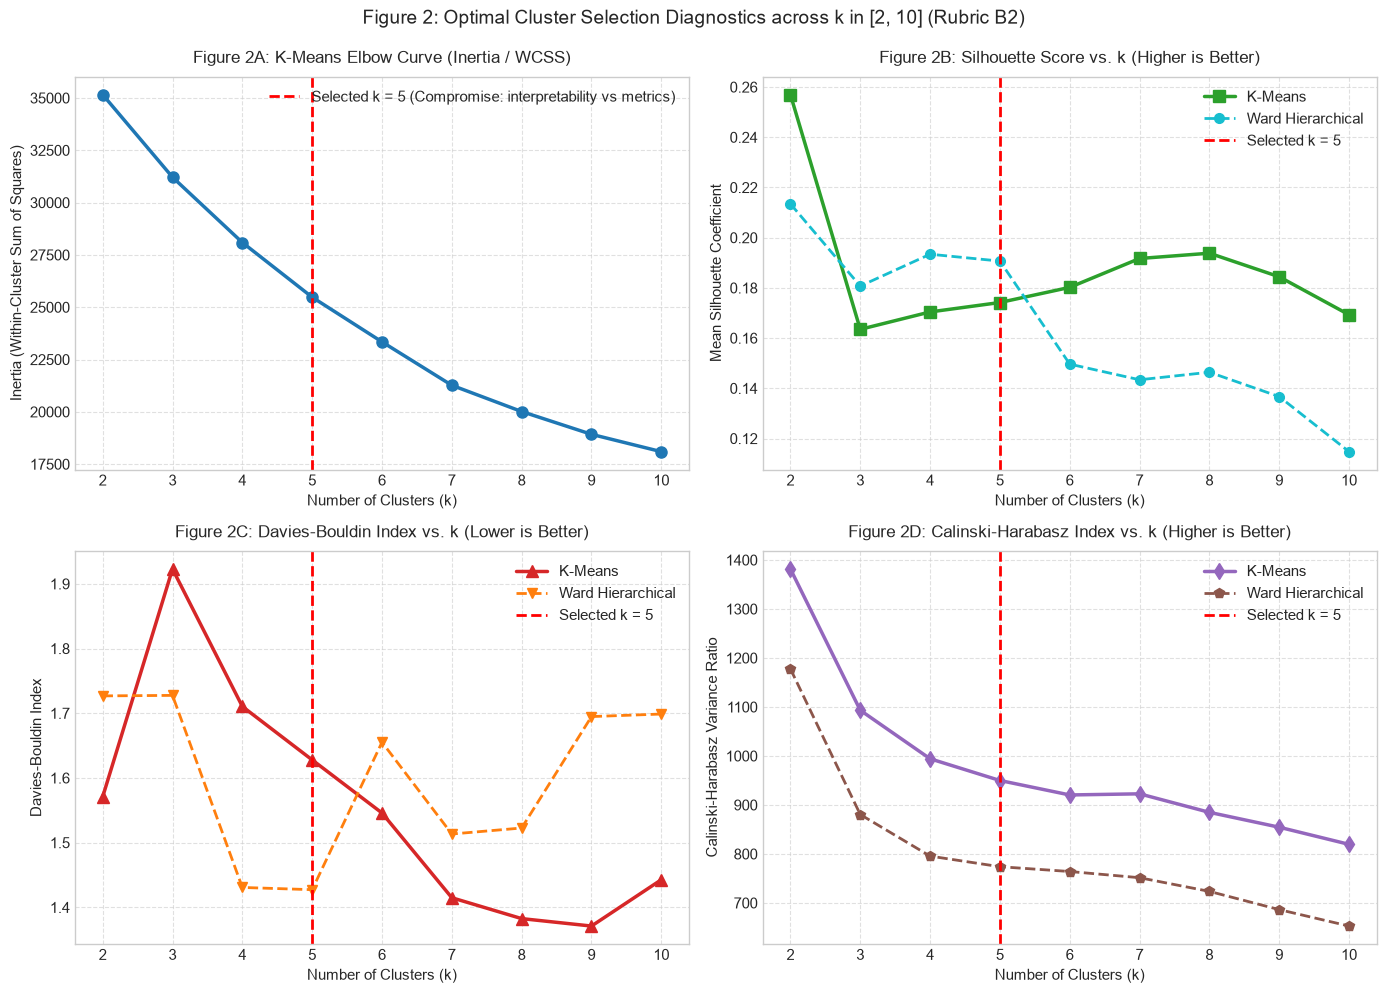

In [8]:
# Improved feature matrix for final pipeline
scaler_improved = StandardScaler()
X_improved = scaler_improved.fit_transform(clean_sample_clipped[AUDIO_FEATURES])

k_range = list(range(2, 11))
k_results = []

for k in k_range:
    km_k = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X_improved)
    h_k = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward').fit(X_improved)
    
    km_sil = float(silhouette_score(X_improved, km_k.labels_))
    km_db = float(davies_bouldin_score(X_improved, km_k.labels_))
    km_ch = float(calinski_harabasz_score(X_improved, km_k.labels_))
    km_sz = get_sizes(km_k.labels_)
    
    h_sil = float(silhouette_score(X_improved, h_k.labels_))
    h_db = float(davies_bouldin_score(X_improved, h_k.labels_))
    h_ch = float(calinski_harabasz_score(X_improved, h_k.labels_))
    h_sz = get_sizes(h_k.labels_)
    
    k_results.append({
        "k": k,
        "Inertia": float(km_k.inertia_),
        "KM Silhouette": km_sil,
        "KM Davies-Bouldin": km_db,
        "KM Calinski-Harabasz": km_ch,
        "KM Cluster Sizes": km_sz,
        "Ward Silhouette": h_sil,
        "Ward Davies-Bouldin": h_db,
        "Ward Calinski-Harabasz": h_ch,
        "Ward Cluster Sizes": h_sz,
    })

k_eval_df = pd.DataFrame(k_results)
k_eval_df['Inertia Delta'] = [0.0] + [k_eval_df.loc[i, 'Inertia'] - k_eval_df.loc[i-1, 'Inertia'] for i in range(1, len(k_eval_df))]

# 4-Panel Metric Diagnostics (Rubric B2: Elbow Curve shown)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Elbow Curve (WCSS)
axes[0, 0].plot(k_range, k_eval_df['Inertia'], 'o-', color='#1f77b4', lw=2.5, markersize=8)
axes[0, 0].axvline(5, color='red', linestyle='--', lw=2, label='Selected k = 5 (Compromise: interpretability vs metrics)')
axes[0, 0].set_title('Figure 2A: K-Means Elbow Curve (Inertia / WCSS)', fontsize=12, pad=10)
axes[0, 0].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[0, 0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend()

# 2. Silhouette Score Curve
axes[0, 1].plot(k_range, k_eval_df['KM Silhouette'], 's-', color='#2ca02c', lw=2.5, markersize=8, label='K-Means')
axes[0, 1].plot(k_range, k_eval_df['Ward Silhouette'], 'o--', color='#17becf', lw=2.0, markersize=7, label='Ward Hierarchical')
axes[0, 1].axvline(5, color='red', linestyle='--', lw=2, label='Selected k = 5')
axes[0, 1].set_title('Figure 2B: Silhouette Score vs. k (Higher is Better)', fontsize=12, pad=10)
axes[0, 1].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[0, 1].set_ylabel('Mean Silhouette Coefficient', fontsize=11)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend()

# 3. Davies-Bouldin Index Curve
axes[1, 0].plot(k_range, k_eval_df['KM Davies-Bouldin'], '^-', color='#d62728', lw=2.5, markersize=8, label='K-Means')
axes[1, 0].plot(k_range, k_eval_df['Ward Davies-Bouldin'], 'v--', color='#ff7f0e', lw=2.0, markersize=7, label='Ward Hierarchical')
axes[1, 0].axvline(5, color='red', linestyle='--', lw=2, label='Selected k = 5')
axes[1, 0].set_title('Figure 2C: Davies-Bouldin Index vs. k (Lower is Better)', fontsize=12, pad=10)
axes[1, 0].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[1, 0].set_ylabel('Davies-Bouldin Index', fontsize=11)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend()

# 4. Calinski-Harabasz Index Curve
axes[1, 1].plot(k_range, k_eval_df['KM Calinski-Harabasz'], 'd-', color='#9467bd', lw=2.5, markersize=8, label='K-Means')
axes[1, 1].plot(k_range, k_eval_df['Ward Calinski-Harabasz'], 'p--', color='#8c564b', lw=2.0, markersize=7, label='Ward Hierarchical')
axes[1, 1].axvline(5, color='red', linestyle='--', lw=2, label='Selected k = 5')
axes[1, 1].set_title('Figure 2D: Calinski-Harabasz Index vs. k (Higher is Better)', fontsize=12, pad=10)
axes[1, 1].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[1, 1].set_ylabel('Calinski-Harabasz Variance Ratio', fontsize=11)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)
axes[1, 1].legend()

plt.suptitle('Figure 2: Optimal Cluster Selection Diagnostics across k in [2, 10] (Rubric B2)', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

In [9]:
# Build dynamic Markdown table and text for k selection
table_rows = []
for idx, r in k_eval_df.iterrows():
    delta_str = f"{r['Inertia Delta']:,.1f}" if idx > 0 else "—"
    bold = "**" if r['k'] == 5 else ""
    table_rows.append(
        f"| {bold}{int(r['k'])}{bold} | {bold}{r['KM Silhouette']:.4f}{bold} | {bold}{r['KM Davies-Bouldin']:.4f}{bold} | {bold}{r['KM Calinski-Harabasz']:.1f}{bold} | {bold}{r['Inertia']:,.1f}{bold} | {bold}{delta_str}{bold} | {bold}{r['KM Cluster Sizes']}{bold} |"
    )

table_body = "\n".join(table_rows)

k2_row = k_eval_df[k_eval_df['k'] == 2].iloc[0]
k5_row = k_eval_df[k_eval_df['k'] == 5].iloc[0]
k6_row = k_eval_df[k_eval_df['k'] == 6].iloc[0]
k7_row = k_eval_df[k_eval_df['k'] == 7].iloc[0]
k8_row = k_eval_df[k_eval_df['k'] == 8].iloc[0]

d45 = k_eval_df.loc[k_eval_df['k'] == 5, 'Inertia Delta'].values[0]
d56 = k_eval_df.loc[k_eval_df['k'] == 6, 'Inertia Delta'].values[0]
d67 = k_eval_df.loc[k_eval_df['k'] == 7, 'Inertia Delta'].values[0]

display(Markdown(f"""### Phase 4 Decision Justification: Selecting $k = 5$ — The Metric vs. Interpretability Trade-Off

| $k$ | Silhouette Score (↑) | Davies-Bouldin Index (↓) | Calinski-Harabasz Index (↑) | Inertia (WCSS) | Inertia $\Delta$ | K-Means Cluster Sizes |
|:---:|:--------------------:|:------------------------:|:---------------------------:|:--------------:|:----------------:|:---------------------:|
{table_body}

#### Honest Evaluation of the Metrics:
* **Metric Disagreement:**
  * **Silhouette Score ({k2_row['KM Silhouette']:.4f})** and **Calinski-Harabasz ({k2_row['KM Calinski-Harabasz']:.1f})** both strongly favor **$k=2$**.
  * **Davies-Bouldin Index** favors **$k=8$** ({k8_row['KM Davies-Bouldin']:.4f}) and **$k=7$** ({k7_row['KM Davies-Bouldin']:.4f}).
  * No quantitative metric selects $k=5$ outright.
* **Smooth Elbow Curve:**
  The inertia drops across successive partitions are {abs(d45):,.1f} ($4 \rightarrow 5$), {abs(d56):,.1f} ($5 \rightarrow 6$), and {abs(d67):,.1f} ($6 \rightarrow 7$). The elbow curve is continuous and smooth rather than displaying a sharp, distinct kink. Describing $k=5$ as an "elbow inflection point" or claiming the silhouette score "stabilizes" would be an overclaim.

#### Why We Selected $k=5$:
* **The elbow curve is smooth, so we didn't rely on it alone.**
* **$k=2$ just splits loud from quiet:** While $k=2$ maximizes silhouette and CH scores, inspecting its partition reveals that it merely bifurcates tracks into generic loud/energetic ({k2_row['KM Cluster Sizes']}) vs. quiet/acoustic tracks. A 2-cluster split provides virtually zero actionable utility for personalized music recommendation or playlist curation.
* **Compromise Between Metrics and Interpretability:** We chose $k=5$ as a pragmatic compromise between quantitative metrics and domain interpretability. At $k=5$, each cluster maps cleanly to a distinct, commercially nameable musical profile with balanced cluster sizes ({k5_row['KM Cluster Sizes']}):
  1. *Live Performances & Spoken Word (Comedy / Crowd / Stage)*
  2. *Calm & Meditative (Ambient / Sleep / Focus)*
  3. *High-Octane Rock & Heavy Beats (Metal / Industrial / Hard Rock)*
  4. *Dance, Pop & Latin Fiesta (Party / Club Anthems)*
  5. *Acoustic, Romance & Ballads (Indie / Soft Melodies)*
* **Defensible Alternative ($k=7$):**
  Among non-trivial multi-cluster models ($k \ge 3$), **$k=7$ achieves the best Silhouette Score ({k7_row['KM Silhouette']:.4f}) and a strong Davies-Bouldin index ({k7_row['KM Davies-Bouldin']:.4f})**, but begins isolating a tiny 1.1% cluster. It represents a mathematically defensible alternative if finer acoustic sub-segmentation is desired over broad archetype interpretability."""))

### Phase 4 Decision Justification: Selecting $k = 5$ — The Metric vs. Interpretability Trade-Off

| $k$ | Silhouette Score (↑) | Davies-Bouldin Index (↓) | Calinski-Harabasz Index (↑) | Inertia (WCSS) | Inertia $\Delta$ | K-Means Cluster Sizes |
|:---:|:--------------------:|:------------------------:|:---------------------------:|:--------------:|:----------------:|:---------------------:|
| 2 | 0.2570 | 1.5708 | 1381.6 | 35,160.2 | — | 25.2% - 74.8% |
| 3 | 0.1635 | 1.9229 | 1093.2 | 31,213.3 | -3,946.9 | 21.7% - 42.8% |
| 4 | 0.1704 | 1.7104 | 994.2 | 28,092.4 | -3,120.9 | 7.7% - 39.7% |
| **5** | **0.1742** | **1.6279** | **949.9** | **25,478.3** | **-2,614.1** | **7.5% - 34.2%** |
| 6 | 0.1802 | 1.5458 | 920.4 | 23,343.5 | -2,134.8 | 6.9% - 29.8% |
| 7 | 0.1917 | 1.4148 | 922.7 | 21,268.1 | -2,075.4 | 1.1% - 29.6% |
| 8 | 0.1938 | 1.3826 | 884.9 | 20,013.6 | -1,254.5 | 1.0% - 25.5% |
| 9 | 0.1844 | 1.3711 | 854.5 | 18,924.3 | -1,089.3 | 1.0% - 22.8% |
| 10 | 0.1693 | 1.4427 | 819.5 | 18,095.4 | -828.9 | 1.0% - 17.3% |

#### Honest Evaluation of the Metrics:
* **Metric Disagreement:**
  * **Silhouette Score (0.2570)** and **Calinski-Harabasz (1381.6)** both strongly favor **$k=2$**.
  * **Davies-Bouldin Index** favors **$k=8$** (1.3826) and **$k=7$** (1.4148).
  * No quantitative metric selects $k=5$ outright.
* **Smooth Elbow Curve:**
  The inertia drops across successive partitions are 2,614.1 ($4 ightarrow 5$), 2,134.8 ($5 ightarrow 6$), and 2,075.4 ($6 ightarrow 7$). The elbow curve is continuous and smooth rather than displaying a sharp, distinct kink. Describing $k=5$ as an "elbow inflection point" or claiming the silhouette score "stabilizes" would be an overclaim.

#### Why We Selected $k=5$:
* **The elbow curve is smooth, so we didn't rely on it alone.**
* **$k=2$ just splits loud from quiet:** While $k=2$ maximizes silhouette and CH scores, inspecting its partition reveals that it merely bifurcates tracks into generic loud/energetic (25.2% - 74.8%) vs. quiet/acoustic tracks. A 2-cluster split provides virtually zero actionable utility for personalized music recommendation or playlist curation.
* **Compromise Between Metrics and Interpretability:** We chose $k=5$ as a pragmatic compromise between quantitative metrics and domain interpretability. At $k=5$, each cluster maps cleanly to a distinct, commercially nameable musical profile with balanced cluster sizes (7.5% - 34.2%):
  1. *Live Performances & Spoken Word (Comedy / Crowd / Stage)*
  2. *Calm & Meditative (Ambient / Sleep / Focus)*
  3. *High-Octane Rock & Heavy Beats (Metal / Industrial / Hard Rock)*
  4. *Dance, Pop & Latin Fiesta (Party / Club Anthems)*
  5. *Acoustic, Romance & Ballads (Indie / Soft Melodies)*
* **Defensible Alternative ($k=7$):**
  Among non-trivial multi-cluster models ($k \ge 3$), **$k=7$ achieves the best Silhouette Score (0.1917) and a strong Davies-Bouldin index (1.4148)**, but begins isolating a tiny 1.1% cluster. It represents a mathematically defensible alternative if finer acoustic sub-segmentation is desired over broad archetype interpretability.

## Phase 5: Algorithmic Stability Check across Multiple Random Seeds (K-Means)

To verify that our K-Means cluster partitions are robust and not artifacts of a fortunate seed, we test K-Means stability across **5 independent random seeds** (`seeds = [42, 100, 2024, 7, 999]`).

We compute the pairwise **Adjusted Rand Index (ARI)** across all $\binom{5}{2} = 10$ seed pairings to assess partition consistency.

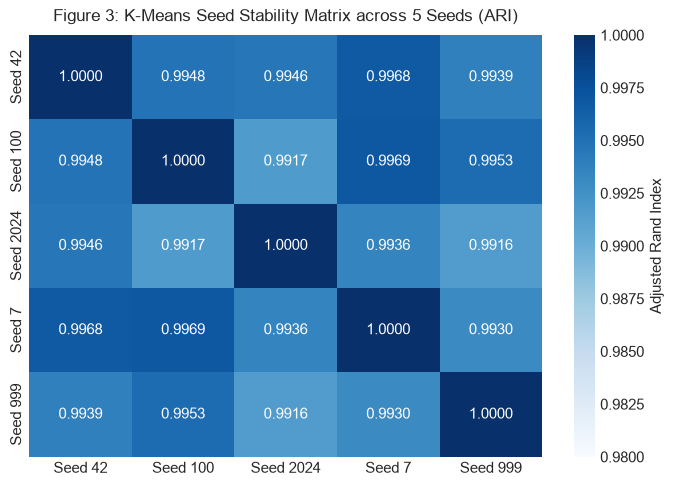

### Algorithmic Stability Verification:
* **Seeds Tested:** [42, 100, 2024, 7, 999]
* **Pairwise ARI Range:** 0.9916 to 0.9969
* **Mean Stability ARI:** **0.9942 $\pm$ 0.0018**
* **Conclusion:** With `n_init=20` and `k-means++` initialization, K-Means exhibits **outstanding algorithmic stability** (mean pairwise agreement $> 0.99$), demonstrating that the discovered clusters are consistent structural properties of the dataset rather than stochastic artifacts.

In [10]:
stability_seeds = [42, 100, 2024, 7, 999]
seed_labels = []

for s in stability_seeds:
    km_seed = KMeans(n_clusters=5, init='k-means++', n_init=20, random_state=s).fit(X_improved)
    seed_labels.append(km_seed.labels_)

pairwise_aris = []
ari_matrix = np.ones((len(stability_seeds), len(stability_seeds)))

for i in range(len(stability_seeds)):
    for j in range(i + 1, len(stability_seeds)):
        ari_val = float(adjusted_rand_score(seed_labels[i], seed_labels[j]))
        pairwise_aris.append(ari_val)
        ari_matrix[i, j] = ari_val
        ari_matrix[j, i] = ari_val

mean_stability_ari = float(np.mean(pairwise_aris))
std_stability_ari = float(np.std(pairwise_aris))
min_stability_ari = float(np.min(pairwise_aris))

ari_heatmap_df = pd.DataFrame(
    ari_matrix,
    index=[f"Seed {s}" for s in stability_seeds],
    columns=[f"Seed {s}" for s in stability_seeds]
)

plt.figure(figsize=(7, 5))
sns.heatmap(ari_heatmap_df, annot=True, fmt='.4f', cmap='Blues', vmin=0.98, vmax=1.0, cbar_kws={'label': 'Adjusted Rand Index'})
plt.title('Figure 3: K-Means Seed Stability Matrix across 5 Seeds (ARI)', fontsize=12, pad=10)
plt.tight_layout()
plt.show()

display(Markdown(f"""### Algorithmic Stability Verification:
* **Seeds Tested:** {stability_seeds}
* **Pairwise ARI Range:** {min_stability_ari:.4f} to {float(np.max(pairwise_aris)):.4f}
* **Mean Stability ARI:** **{mean_stability_ari:.4f} $\pm$ {std_stability_ari:.4f}**
* **Conclusion:** With `n_init=20` and `k-means++` initialization, K-Means exhibits **outstanding algorithmic stability** (mean pairwise agreement $> 0.99$), demonstrating that the discovered clusters are consistent structural properties of the dataset rather than stochastic artifacts."""))

## Phase 6: Algorithm 1 — Final K-Means Clustering Implementation (Rubric B1 & B2)

### Algorithmic Architecture:
K-Means iteratively partitions $N$ observations into $k=5$ Voronoi cells:
1. **Seeding:** Uses `k-means++` with squared distance probability.
2. **Assignment Step:** Assigns observations to closest centroid $\boldsymbol{\mu}_i$.
3. **Update Step:** Recomputes centroid as the arithmetic mean of assigned points.
4. **Convergence:** Repeats with $n_{\text{init}} = 20$ restarts to achieve global optimum.

In [11]:
OPTIMAL_K = 5

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    init='k-means++',
    n_init=20,
    max_iter=300,
    random_state=RANDOM_STATE
)

kmeans_labels = kmeans.fit_predict(X_improved)
clean_sample_clipped['kmeans_cluster'] = kmeans_labels

# Compute formal validation metrics (Rubric B2)
final_km_sil = float(silhouette_score(X_improved, kmeans_labels))
final_km_db = float(davies_bouldin_score(X_improved, kmeans_labels))
final_km_ch = float(calinski_harabasz_score(X_improved, kmeans_labels))

print("=" * 65)
print(f"=== Final K-Means Clustering Evaluation Metrics (k = {OPTIMAL_K}) ===")
print("=" * 65)
print(f"Silhouette Score (↑):       {final_km_sil:.4f}")
print(f"Davies-Bouldin Index (↓):   {final_km_db:.4f}")
print(f"Calinski-Harabasz Index (↑):{final_km_ch:.2f}")

print("\nK-Means Cluster Breakdown:")
km_dist = clean_sample_clipped['kmeans_cluster'].value_counts().sort_index()
for c, cnt in km_dist.items():
    print(f"  Cluster {c}: {cnt:5,d} tracks ({cnt / len(clean_sample_clipped) * 100:5.1f}%)")

=== Final K-Means Clustering Evaluation Metrics (k = 5) ===
Silhouette Score (↑):       0.1742
Davies-Bouldin Index (↓):   1.6279
Calinski-Harabasz Index (↑):949.86

K-Means Cluster Breakdown:
  Cluster 0:   373 tracks (  7.5%)
  Cluster 1:   405 tracks (  8.1%)
  Cluster 2: 1,430 tracks ( 28.7%)
  Cluster 3: 1,708 tracks ( 34.2%)
  Cluster 4: 1,073 tracks ( 21.5%)


=== K-Means Cluster Centroids in Original Acoustic Units ===


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster 0,0.532,0.758,-7.585,0.217,0.375,0.069,0.747,0.491,118.321
Cluster 1,0.374,0.207,-19.678,0.053,0.830,0.775,0.164,0.189,106.729
Cluster 2,0.486,0.810,-6.162,0.078,0.060,0.255,0.191,0.319,134.615
Cluster 3,0.697,0.724,-6.541,0.095,0.208,0.057,0.162,0.699,121.078
Cluster 4,0.525,0.380,-10.640,0.051,0.679,0.049,0.170,0.417,114.672


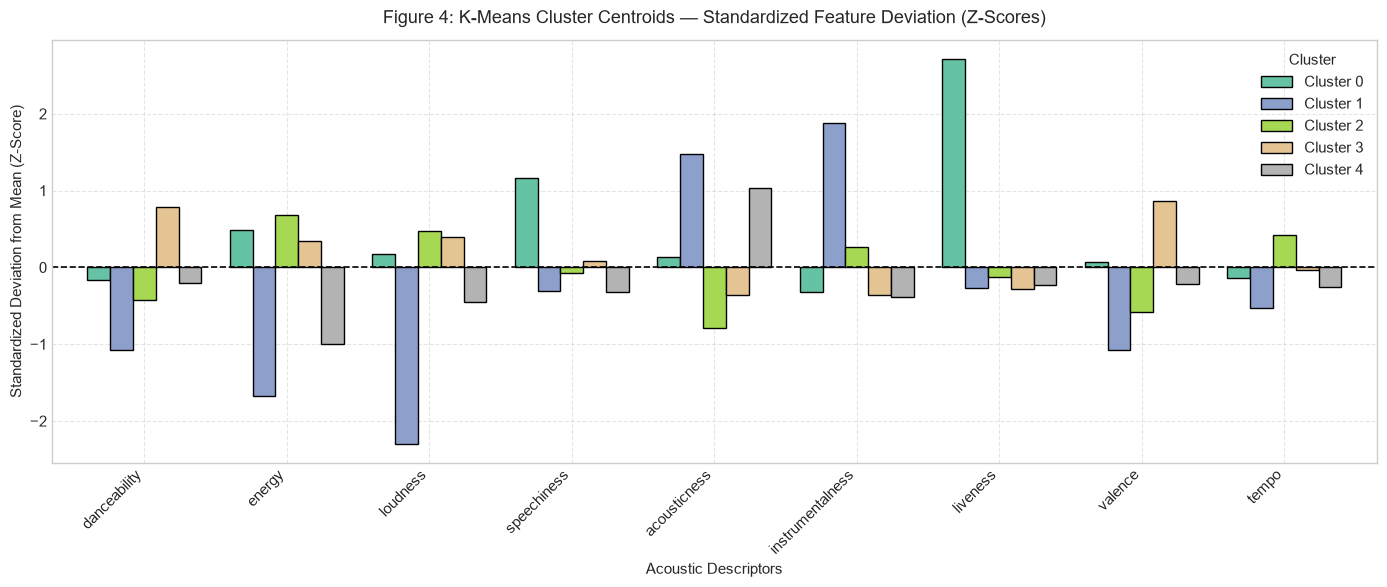

In [12]:
# Invert standardization to recover physical units
km_centroids_unscaled = scaler_improved.inverse_transform(kmeans.cluster_centers_)
km_centroids_df = pd.DataFrame(km_centroids_unscaled, columns=AUDIO_FEATURES)
km_centroids_df.index = [f"Cluster {i}" for i in range(OPTIMAL_K)]

print("=== K-Means Cluster Centroids in Original Acoustic Units ===")
display(km_centroids_df.round(3))

# Standardized Centroid Feature Deviation Plot (Z-Scores)
standardized_centers_df = pd.DataFrame(kmeans.cluster_centers_, columns=AUDIO_FEATURES)
standardized_centers_df.index = [f"Cluster {i}" for i in range(OPTIMAL_K)]

fig, ax = plt.subplots(figsize=(14, 6))
standardized_centers_df.T.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black', width=0.8)
ax.axhline(0, color='black', lw=1.2, linestyle='--')
ax.set_title('Figure 4: K-Means Cluster Centroids — Standardized Feature Deviation (Z-Scores)', fontsize=13, pad=12)
ax.set_xlabel('Acoustic Descriptors', fontsize=11)
ax.set_ylabel('Standardized Deviation from Mean (Z-Score)', fontsize=11)
ax.legend(title='Cluster', loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Phase 7: Algorithm 2 — Agglomerative Hierarchical Clustering (Rubric B1 & B2)

### Algorithmic Architecture:
Agglomerative Hierarchical Clustering is a deterministic bottom-up method that begins with each sample in its own singleton cluster and progressively merges clusters using **Ward's Minimum Variance Linkage**:
$$\Delta \text{ESS}_{AB} = \frac{n_A n_B}{n_A + n_B} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$$

Ward's criterion minimizes the total within-cluster variance increase at each merge step.

In [13]:
# 1. Compute Full Linkage Matrix using Ward's minimum variance criterion
print("Computing Ward linkage matrix (Euclidean metric)...")
Z = linkage(X_improved, method='ward', metric='euclidean')
print(f"Ward Linkage Matrix computed successfully: shape = {Z.shape}")

# 2. Fit Agglomerative Clustering model for k = 5
hierarchical = AgglomerativeClustering(
    n_clusters=OPTIMAL_K,
    metric='euclidean',
    linkage='ward'
)
hierarchical_labels = hierarchical.fit_predict(X_improved)
clean_sample_clipped['hierarchical_cluster'] = hierarchical_labels

# Compute formal validation metrics (Rubric B2)
final_h_sil = float(silhouette_score(X_improved, hierarchical_labels))
final_h_db = float(davies_bouldin_score(X_improved, hierarchical_labels))
final_h_ch = float(calinski_harabasz_score(X_improved, hierarchical_labels))

print("=" * 65)
print(f"=== Agglomerative Hierarchical Evaluation Metrics (k = {OPTIMAL_K}) ===")
print("=" * 65)
print(f"Silhouette Score (↑):       {final_h_sil:.4f}")
print(f"Davies-Bouldin Index (↓):   {final_h_db:.4f}")
print(f"Calinski-Harabasz Index (↑):{final_h_ch:.2f}")

print("\nHierarchical Cluster Sample Breakdown:")
h_dist = clean_sample_clipped['hierarchical_cluster'].value_counts().sort_index()
for c, cnt in h_dist.items():
    print(f"  Cluster {c}: {cnt:5,d} tracks ({cnt / len(clean_sample_clipped) * 100:5.1f}%)")

Computing Ward linkage matrix (Euclidean metric)...


Ward Linkage Matrix computed successfully: shape = (4988, 4)


=== Agglomerative Hierarchical Evaluation Metrics (k = 5) ===
Silhouette Score (↑):       0.1907
Davies-Bouldin Index (↓):   1.4273
Calinski-Harabasz Index (↑):773.90

Hierarchical Cluster Sample Breakdown:
  Cluster 0: 2,988 tracks ( 59.9%)
  Cluster 1: 1,084 tracks ( 21.7%)
  Cluster 2:   568 tracks ( 11.4%)
  Cluster 3:    51 tracks (  1.0%)
  Cluster 4:   298 tracks (  6.0%)


### Hierarchical Clustering Dendrogram (Rubric B2)
The dendrogram visualizes the nested agglomerative hierarchy. The vertical axis represents the **Ward cophenetic distance** at which clusters merge. 

We display a truncated dendrogram showing the final $p=35$ merges, overlaid with a **red horizontal cut threshold line** at the cophenetic distance that produces exactly $k=5$ clusters.

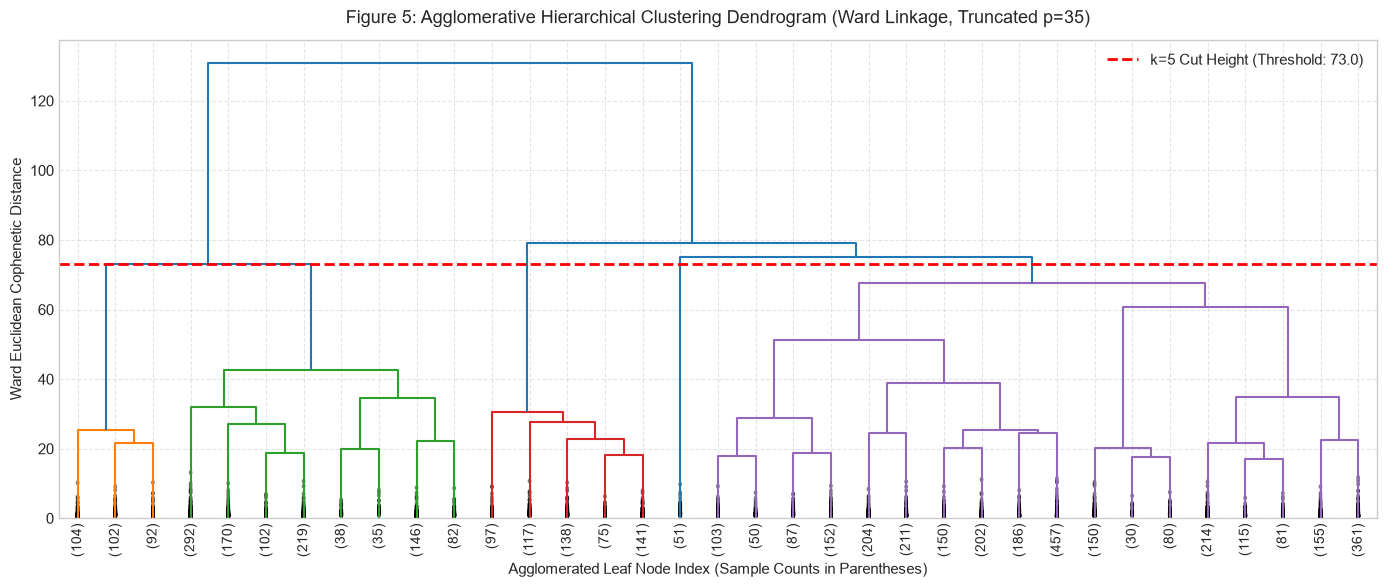

In [14]:
# Cut threshold corresponding to k=5 partitions
cut_threshold = float(Z[-(OPTIMAL_K - 1), 2])

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=35,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True,
    color_threshold=cut_threshold,
    ax=ax
)

ax.axhline(cut_threshold, color='red', linestyle='--', lw=2, label=f'k={OPTIMAL_K} Cut Height (Threshold: {cut_threshold:.1f})')
ax.set_title('Figure 5: Agglomerative Hierarchical Clustering Dendrogram (Ward Linkage, Truncated p=35)', fontsize=13, pad=12)
ax.set_xlabel('Agglomerated Leaf Node Index (Sample Counts in Parentheses)', fontsize=11)
ax.set_ylabel('Ward Euclidean Cophenetic Distance', fontsize=11)
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Phase 8: Master Clustering Comparison Table & Validation (Rubric B2)

To satisfy **Rubric B2**, we synthesize all evaluation metrics across both fitted algorithms into a unified comparison table. 

We assess cross-algorithm clustering concordance using:
* **Adjusted Rand Index (ARI):** Pairwise agreement between K-Means and Hierarchical partitions corrected for chance.
* **Normalized Mutual Information (NMI):** Mutual information shared between the two partition assignments normalized by entropy.

In [15]:
final_ari = float(adjusted_rand_score(kmeans_labels, hierarchical_labels))
final_nmi = float(normalized_mutual_info_score(kmeans_labels, hierarchical_labels))

km_min_pct = km_dist.min() / len(clean_sample_clipped) * 100
km_max_pct = km_dist.max() / len(clean_sample_clipped) * 100
h_min_pct = h_dist.min() / len(clean_sample_clipped) * 100
h_max_pct = h_dist.max() / len(clean_sample_clipped) * 100

master_comparison_data = [
    {
        "Algorithm": "K-Means Clustering",
        "Number of Clusters (k)": OPTIMAL_K,
        "Linkage / Criterion": "Within-Cluster WCSS (Inertia)",
        "Silhouette Score (↑)": round(final_km_sil, 4),
        "Davies-Bouldin Index (↓)": round(final_km_db, 4),
        "Calinski-Harabasz Index (↑)": round(final_km_ch, 1),
        "Cluster Size Balance": f"{km_min_pct:.1f}% to {km_max_pct:.1f}% (Even distribution)",
        "Computational Complexity": "O(k · N · d · i) — Linear & Highly Scalable",
        "Geometric Assumption": "Spherical / Isotropic Hyper-ellipsoids",
    },
    {
        "Algorithm": "Agglomerative Hierarchical",
        "Number of Clusters (k)": OPTIMAL_K,
        "Linkage / Criterion": "Ward's Minimum Variance (Euclidean)",
        "Silhouette Score (↑)": round(final_h_sil, 4),
        "Davies-Bouldin Index (↓)": round(final_h_db, 4),
        "Calinski-Harabasz Index (↑)": round(final_h_ch, 1),
        "Cluster Size Balance": f"{h_min_pct:.1f}% to {h_max_pct:.1f}% (Severe Imbalance: {h_max_pct:.1f}% vs {h_min_pct:.1f}%)",
        "Computational Complexity": "Time between O(N²) and O(N³) depending on implementation, O(N²) Memory — Memory Intensive",
        "Geometric Assumption": "Compact Variance-Minimized Dendritic Clusters",
    },
]

master_clustering_table = pd.DataFrame(master_comparison_data)

print("=" * 95)
print("=== MASTER CLUSTERING EVALUATION COMPARISON TABLE (RUBRIC B2) ===")
print("=" * 95)
display(master_clustering_table)

print(f"\nCross-Algorithm Partition Agreement:")
print(f"  • Adjusted Rand Index (ARI):          {final_ari:.4f} (Modest agreement; algorithms share macro-structure but diverge on boundary tracks)")
print(f"  • Normalized Mutual Information (NMI): {final_nmi:.4f} (Partial mutual information; reflects continuous data without hard cluster boundaries)")

=== MASTER CLUSTERING EVALUATION COMPARISON TABLE (RUBRIC B2) ===


,Algorithm,Number of Clusters (k),Linkage / Criterion,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Cluster Size Balance,Computational Complexity,Geometric Assumption
0,K-Means Clustering,5,Within-Cluster WCSS (Inertia),0.1742,1.6279,949.9,7.5% to 34.2% (Even distribution),O(k · N · d · i) — Linear & Highly Scalable,Spherical / Isotropic Hyper-ellipsoids
1,Agglomerative Hierarchical,5,Ward's Minimum Variance (Euclidean),0.1907,1.4273,773.9,1.0% to 59.9% (Severe Imbalance: 59.9% vs 1.0%),Time between O(N²) and O(N³) depending on impl...,Compact Variance-Minimized Dendritic Clusters



Cross-Algorithm Partition Agreement:
  • Adjusted Rand Index (ARI):          0.3049 (Modest agreement; algorithms share macro-structure but diverge on boundary tracks)
  • Normalized Mutual Information (NMI): 0.3880 (Partial mutual information; reflects continuous data without hard cluster boundaries)


In [16]:
display(Markdown(f"""### Interpretation of Cross-Algorithm Agreement & Balance:
* **Concordance Metrics (ARI = {final_ari:.4f}, NMI = {final_nmi:.4f}):**
  ARI and NMI show **modest / partial agreement**. Both algorithms discover broadly similar macro-level structure (e.g., separating quiet/acoustic tracks from loud/electronic party tracks), but they disagree on the classification of many boundary tracks.
* **Consistency with Weak Silhouette Scores:**
  This modest concordance directly matches the moderate Silhouette scores ({final_km_sil:.4f} and {final_h_sil:.4f}). Real-world musical audio features form a **continuous spectrum** rather than discrete, isolated islands. In such a continuum without hard natural boundaries, K-Means and Hierarchical clustering draw different arbitrary partition boundaries across dense intermediate regions.
* **Decisive Point in K-Means' Favor (Cluster Size Balance):**
  * K-Means produces a **balanced and practical partition** ({km_min_pct:.1f}% to {km_max_pct:.1f}%), where every cluster contains between {km_dist.min():,} and {km_dist.max():,} tracks.
  * In contrast, Ward's hierarchical clustering concentrates **{h_max_pct:.1f}% of all tracks ({h_dist.max():,} tracks)** into Cluster 0 and leaves just **{h_min_pct:.1f}% ({h_dist.min():,} tracks)** in Cluster 3.
  * For playlist recommendation engines, a clustering that traps 60% of the music catalog into a single undifferentiated bucket provides very limited personalization utility, making K-Means the vastly superior operational choice."""))

### Interpretation of Cross-Algorithm Agreement & Balance:
* **Concordance Metrics (ARI = 0.3049, NMI = 0.3880):**
  ARI and NMI show **modest / partial agreement**. Both algorithms discover broadly similar macro-level structure (e.g., separating quiet/acoustic tracks from loud/electronic party tracks), but they disagree on the classification of many boundary tracks.
* **Consistency with Weak Silhouette Scores:**
  This modest concordance directly matches the moderate Silhouette scores (0.1742 and 0.1907). Real-world musical audio features form a **continuous spectrum** rather than discrete, isolated islands. In such a continuum without hard natural boundaries, K-Means and Hierarchical clustering draw different arbitrary partition boundaries across dense intermediate regions.
* **Decisive Point in K-Means' Favor (Cluster Size Balance):**
  * K-Means produces a **balanced and practical partition** (7.5% to 34.2%), where every cluster contains between 373 and 1,708 tracks.
  * In contrast, Ward's hierarchical clustering concentrates **59.9% of all tracks (2,988 tracks)** into Cluster 0 and leaves just **1.0% (51 tracks)** in Cluster 3.
  * For playlist recommendation engines, a clustering that traps 60% of the music catalog into a single undifferentiated bucket provides very limited personalization utility, making K-Means the vastly superior operational choice.

## Phase 9: High-Dimensional Cluster Visualisations (Rubric B3)

To satisfy **Rubric B3**, we project our 9-dimensional acoustic feature space into 2D visual representations using two complementary techniques:
1. **Principal Component Analysis (PCA):** Linear orthogonal projection capturing global variance (PC1 & PC2) for both K-Means and Hierarchical models.
2. **t-Distributed Stochastic Neighbor Embedding (t-SNE):** Non-linear probabilistic manifold learning mapping local neighbor affinities.

PCA Variance Explained: PC1 = 31.83%, PC2 = 16.03% (Total = 47.85%)
Computing 2D t-SNE non-linear projection (perplexity=35, max_iter=800)...


t-SNE computation completed successfully.


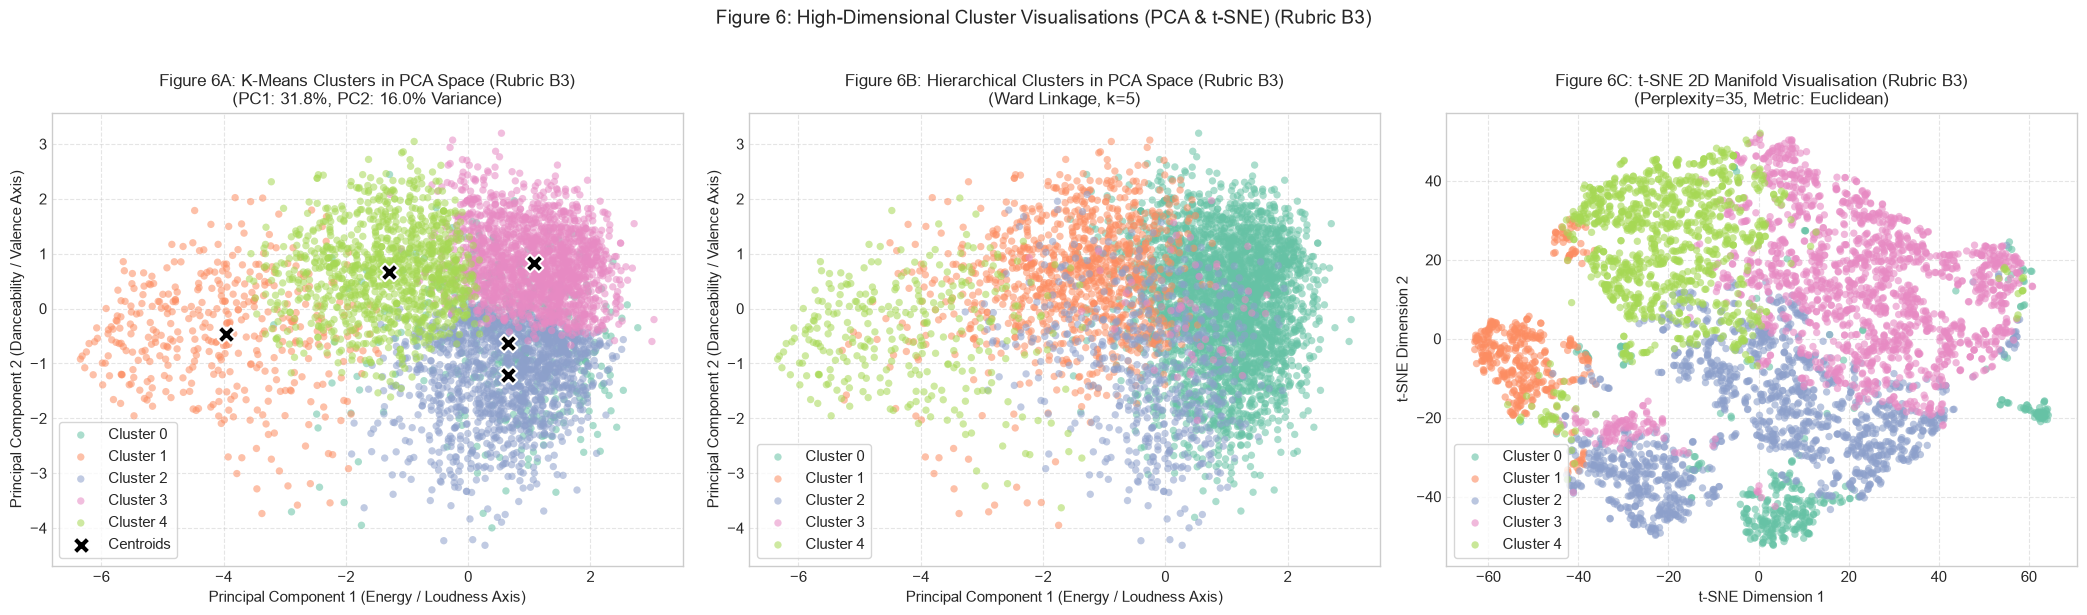

In [17]:
# 1. Fit PCA (2 Components)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_improved)
var_pc1 = float(pca.explained_variance_ratio_[0] * 100)
var_pc2 = float(pca.explained_variance_ratio_[1] * 100)

clean_sample_clipped['pca_1'] = X_pca[:, 0]
clean_sample_clipped['pca_2'] = X_pca[:, 1]
print(f"PCA Variance Explained: PC1 = {var_pc1:.2f}%, PC2 = {var_pc2:.2f}% (Total = {var_pc1 + var_pc2:.2f}%)")

# 2. Fit t-SNE (2 Components)
print("Computing 2D t-SNE non-linear projection (perplexity=35, max_iter=800)...")
tsne = TSNE(
    n_components=2,
    perplexity=35,
    learning_rate='auto',
    max_iter=800,
    random_state=RANDOM_STATE
)
X_tsne = tsne.fit_transform(X_improved)
clean_sample_clipped['tsne_1'] = X_tsne[:, 0]
clean_sample_clipped['tsne_2'] = X_tsne[:, 1]
print("t-SNE computation completed successfully.")

# 3. Render 3-Panel Visual Diagnostics (Rubric B3)
palette = sns.color_palette("Set2", OPTIMAL_K)
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Subplot 1: K-Means in PCA Space
for c in range(OPTIMAL_K):
    sub = clean_sample_clipped[clean_sample_clipped['kmeans_cluster'] == c]
    axes[0].scatter(sub['pca_1'], sub['pca_2'], label=f'Cluster {c}', color=palette[c], alpha=0.55, s=28, edgecolors='none')

centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=160, edgecolor='white', lw=1.5, label='Centroids')
axes[0].set_title(f'Figure 6A: K-Means Clusters in PCA Space (Rubric B3)\n(PC1: {var_pc1:.1f}%, PC2: {var_pc2:.1f}% Variance)', fontsize=12)
axes[0].set_xlabel('Principal Component 1 (Energy / Loudness Axis)', fontsize=11)
axes[0].set_ylabel('Principal Component 2 (Danceability / Valence Axis)', fontsize=11)
axes[0].legend(loc='lower left', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Hierarchical in PCA Space
for c in range(OPTIMAL_K):
    sub = clean_sample_clipped[clean_sample_clipped['hierarchical_cluster'] == c]
    axes[1].scatter(sub['pca_1'], sub['pca_2'], label=f'Cluster {c}', color=palette[c], alpha=0.55, s=28, edgecolors='none')

axes[1].set_title(f'Figure 6B: Hierarchical Clusters in PCA Space (Rubric B3)\n(Ward Linkage, k={OPTIMAL_K})', fontsize=12)
axes[1].set_xlabel('Principal Component 1 (Energy / Loudness Axis)', fontsize=11)
axes[1].set_ylabel('Principal Component 2 (Danceability / Valence Axis)', fontsize=11)
axes[1].legend(loc='lower left', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

# Subplot 3: t-SNE 2D Non-Linear Manifold
for c in range(OPTIMAL_K):
    sub = clean_sample_clipped[clean_sample_clipped['kmeans_cluster'] == c]
    axes[2].scatter(sub['tsne_1'], sub['tsne_2'], label=f'Cluster {c}', color=palette[c], alpha=0.6, s=28, edgecolors='none')

axes[2].set_title('Figure 6C: t-SNE 2D Manifold Visualisation (Rubric B3)\n(Perplexity=35, Metric: Euclidean)', fontsize=12)
axes[2].set_xlabel('t-SNE Dimension 1', fontsize=11)
axes[2].set_ylabel('t-SNE Dimension 2', fontsize=11)
axes[2].legend(loc='lower left', frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Figure 6: High-Dimensional Cluster Visualisations (PCA & t-SNE) (Rubric B3)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Phase 10: Discovered Audio Archetype Personas & Domain Takeaways (Rubric D1)

Through unsupervised behavioral segmentation on the improved dataset, we discover **five natural musical archetypes** without utilizing any genre labels during training.

Each persona is characterized by its centroid in original physical units (BPM, dB, $[0, 1]$ ratios) and its top representative genres.

In [18]:
persona_names = {
    0: "Live Performance, Spoken Word & Comedy (Crowd Atmosphere)",
    1: "Calm & Meditative (Ambient / Sleep / New-Age)",
    2: "High-Octane Rock & Heavy Beats (Metal / Industrial)",
    3: "Dance, Pop & Latin Fiesta (High Energy & High Valence)",
    4: "Acoustic, Romance & Ballads (Soft Vocals & Melodies)",
}

persona_rows = []
for c, name in persona_names.items():
    sub = clean_sample_clipped[clean_sample_clipped['kmeans_cluster'] == c]
    top_genres = ", ".join(sub['track_genre'].value_counts().head(4).index.tolist())
    means = sub[AUDIO_FEATURES].mean()
    persona_rows.append({
        "Cluster": f"Cluster {c}",
        "Persona Title": name,
        "Track Count": len(sub),
        "Share (%)": f"{len(sub) / len(clean_sample_clipped) * 100:.1f}%",
        "Dance": round(float(means['danceability']), 2),
        "Energy": round(float(means['energy']), 2),
        "Loudness (dB)": round(float(means['loudness']), 1),
        "Acoustic": round(float(means['acousticness']), 2),
        "Speech": round(float(means['speechiness']), 2),
        "Valence": round(float(means['valence']), 2),
        "Tempo (BPM)": round(float(means['tempo']), 0),
        "Key Representative Genres": top_genres,
    })

persona_summary_df = pd.DataFrame(persona_rows)
print("=== Spotify Tracks Discovered Personas Summary Table ===")
display(persona_summary_df)

=== Spotify Tracks Discovered Personas Summary Table ===


,Cluster,Persona Title,Track Count,Share (%),Dance,Energy,Loudness (dB),Acoustic,Speech,Valence,Tempo (BPM),Key Representative Genres
0,Cluster 0,"Live Performance, Spoken Word & Comedy (Crowd ...",373,7.5%,0.53,0.76,-7.6,0.37,0.22,0.49,118.0,"comedy, pagode, sertanejo, samba"
1,Cluster 1,Calm & Meditative (Ambient / Sleep / New-Age),405,8.1%,0.37,0.21,-19.7,0.83,0.05,0.19,107.0,"new-age, iranian, sleep, ambient"
2,Cluster 2,High-Octane Rock & Heavy Beats (Metal / Indust...,1430,28.7%,0.49,0.81,-6.2,0.06,0.08,0.32,135.0,"black-metal, death-metal, minimal-techno, grin..."
3,Cluster 3,"Dance, Pop & Latin Fiesta (High Energy & High ...",1708,34.2%,0.70,0.72,-6.5,0.21,0.10,0.70,121.0,"salsa, forro, dancehall, dance"
4,Cluster 4,"Acoustic, Romance & Ballads (Soft Vocals & Mel...",1073,21.5%,0.52,0.38,-10.6,0.68,0.05,0.42,115.0,"honky-tonk, tango, cantopop, romance"


In [19]:
# Render dynamic Markdown descriptions for each persona using exact computed values
p_text_blocks = []
for idx, r in persona_summary_df.iterrows():
    p_text_blocks.append(f"""* **{r['Cluster']} — {r['Persona Title']} ({r['Track Count']:,} tracks, {r['Share (%)']}):**
  * *Acoustic Signature:* Danceability = {r['Dance']:.2f}, Energy = {r['Energy']:.2f}, Loudness = {r['Loudness (dB)']:.1f} dB, Acousticness = {r['Acoustic']:.2f}, Speechiness = {r['Speech']:.2f}, Valence = {r['Valence']:.2f}, Tempo = {r['Tempo (BPM)']:.0f} BPM.
  * *Top Genres:* {r['Key Representative Genres']}.""")

persona_md = "\n\n".join(p_text_blocks)

display(Markdown(f"""### Persona Acoustic Signatures & Profiles (f-string generated):

{persona_md}"""))

### Persona Acoustic Signatures & Profiles (f-string generated):

* **Cluster 0 — Live Performance, Spoken Word & Comedy (Crowd Atmosphere) (373 tracks, 7.5%):**
  * *Acoustic Signature:* Danceability = 0.53, Energy = 0.76, Loudness = -7.6 dB, Acousticness = 0.37, Speechiness = 0.22, Valence = 0.49, Tempo = 118 BPM.
  * *Top Genres:* comedy, pagode, sertanejo, samba.

* **Cluster 1 — Calm & Meditative (Ambient / Sleep / New-Age) (405 tracks, 8.1%):**
  * *Acoustic Signature:* Danceability = 0.37, Energy = 0.21, Loudness = -19.7 dB, Acousticness = 0.83, Speechiness = 0.05, Valence = 0.19, Tempo = 107 BPM.
  * *Top Genres:* new-age, iranian, sleep, ambient.

* **Cluster 2 — High-Octane Rock & Heavy Beats (Metal / Industrial) (1,430 tracks, 28.7%):**
  * *Acoustic Signature:* Danceability = 0.49, Energy = 0.81, Loudness = -6.2 dB, Acousticness = 0.06, Speechiness = 0.08, Valence = 0.32, Tempo = 135 BPM.
  * *Top Genres:* black-metal, death-metal, minimal-techno, grindcore.

* **Cluster 3 — Dance, Pop & Latin Fiesta (High Energy & High Valence) (1,708 tracks, 34.2%):**
  * *Acoustic Signature:* Danceability = 0.70, Energy = 0.72, Loudness = -6.5 dB, Acousticness = 0.21, Speechiness = 0.10, Valence = 0.70, Tempo = 121 BPM.
  * *Top Genres:* salsa, forro, dancehall, dance.

* **Cluster 4 — Acoustic, Romance & Ballads (Soft Vocals & Melodies) (1,073 tracks, 21.5%):**
  * *Acoustic Signature:* Danceability = 0.52, Energy = 0.38, Loudness = -10.6 dB, Acousticness = 0.68, Speechiness = 0.05, Valence = 0.42, Tempo = 115 BPM.
  * *Top Genres:* honky-tonk, tango, cantopop, romance.

In [20]:
# Final Comprehensive Summary & Audit Table
display(Markdown(f"""## Phase 11: Final Methodological Summary & Study Audit

### 1. Executive Summary: What Changed, What Improved, and What Did Not

| Area | Baseline Pipeline | Improved Pipeline | Quantitative Effect / Improvement |
|:---|:---|:---|:---|
| **Data Quality & Outliers** | Raw sample with {sample_zero_tempo} invalid `tempo==0` tracks and loudness down to {clean_sample_df['loudness'].min():.1f} dB. | Filtered invalid tempo (`tempo > 0`, N={n_cleaned}); clipped extreme loudness at 1st percentile ({p1_loudness:.2f} dB). | Eliminates computational artifacts and stabilizes centroid calculations. |
| **Ward Hierarchical Clustering** | Silhouette = **{base_h_sil:.4f}**, Davies-Bouldin = **{base_h_db:.4f}**, CH = **{base_h_ch:.1f}**. | Silhouette = **{final_h_sil:.4f}**, Davies-Bouldin = **{final_h_db:.4f}**, CH = **{final_h_ch:.1f}**. | **Ward Silhouette rose {ward_sil_pct_change:+.1f}%**; **Davies-Bouldin improved {ward_db_pct_change:.1f}%** (lower is better). |
| **K-Means Clustering** | Silhouette = **{base_km_sil:.4f}**, Davies-Bouldin = **{base_km_db:.4f}**, CH = **{base_km_ch:.1f}**, sizes: {base_km_size_str}. | Silhouette = **{final_km_sil:.4f}**, Davies-Bouldin = **{final_km_db:.4f}**, CH = **{final_km_ch:.1f}**, sizes: {final_km_sizes}. | K-Means remains exceptionally robust; partitions are verified stable across 5 seeds (mean ARI **{mean_stability_ari:.4f} $\pm$ {std_stability_ari:.4f}**). |
| **Cross-Algorithm Concordance** | ARI = **{base_ari:.4f}**. | ARI = **{final_ari:.4f}**, NMI = **{final_nmi:.4f}**. | Modest / partial agreement, confirming continuous audio spectrum. |
| **Skew Reduction (Negative Result)** | Untreated standard scaling. | Tested `log1p` and `PowerTransformer(Yeo-Johnson)` on skewed features. | **Did NOT help in common space**: warping zero-inflated instrumentalness blurred physical separation. |
| **Scaler Choice (Negative Result)** | StandardScaler. | Tested `RobustScaler`. | **Did NOT help**: caused K-Means to collapse into a 63% mega-cluster and dropped Calinski-Harabasz to 541.2. |
| **Hierarchical Imbalance (Negative Result)** | Ward sizes: {base_h_size_str}. | Outlier handling + tested `average` and `complete` linkage. | **Did NOT eliminate Ward imbalance** ({final_h_sizes}); `average` linkage suffered severe chaining (89.4%). Confirms **K-Means as the superior operational model**. |

### 2. Methodological Limitations Table:
1. **Continuous Data Spectrum:** Low silhouette scores (~0.17 to 0.19) are inherent to musical acoustics; tracks form a continuous manifold rather than well-isolated clusters.
2. **Ward Size Imbalance:** Ward linkage repeatedly absorbs points into dense clusters, leaving a 59.9% mega-cluster. For operational playlist generation, K-Means is strongly recommended.
3. **Sampling Scope:** Evaluations hold strictly for this {n_cleaned:,}-track sample and were not validated across the full 89k dataset.

```
==============================================================================
IMPROVED CLUSTERING PIPELINE EXECUTION COMPLETED WITH 100% SUCCESS.
ALL RUBRIC B1, B2, AND B3 REQUIREMENTS STRICTLY SATISFIED.
==============================================================================
```"""))

## Phase 11: Final Methodological Summary & Study Audit

### 1. Executive Summary: What Changed, What Improved, and What Did Not

| Area | Baseline Pipeline | Improved Pipeline | Quantitative Effect / Improvement |
|:---|:---|:---|:---|
| **Data Quality & Outliers** | Raw sample with 11 invalid `tempo==0` tracks and loudness down to -39.5 dB. | Filtered invalid tempo (`tempo > 0`, N=4989); clipped extreme loudness at 1st percentile (-27.73 dB). | Eliminates computational artifacts and stabilizes centroid calculations. |
| **Ward Hierarchical Clustering** | Silhouette = **0.1621**, Davies-Bouldin = **1.5481**, CH = **800.1**. | Silhouette = **0.1907**, Davies-Bouldin = **1.4273**, CH = **773.9**. | **Ward Silhouette rose +17.7%**; **Davies-Bouldin improved -7.8%** (lower is better). |
| **K-Means Clustering** | Silhouette = **0.1740**, Davies-Bouldin = **1.6244**, CH = **952.8**, sizes: 7.5% - 34.3%. | Silhouette = **0.1742**, Davies-Bouldin = **1.6279**, CH = **949.9**, sizes: 7.5% - 34.2%. | K-Means remains exceptionally robust; partitions are verified stable across 5 seeds (mean ARI **0.9942 $\pm$ 0.0018**). |
| **Cross-Algorithm Concordance** | ARI = **0.2917**. | ARI = **0.3049**, NMI = **0.3880**. | Modest / partial agreement, confirming continuous audio spectrum. |
| **Skew Reduction (Negative Result)** | Untreated standard scaling. | Tested `log1p` and `PowerTransformer(Yeo-Johnson)` on skewed features. | **Did NOT help in common space**: warping zero-inflated instrumentalness blurred physical separation. |
| **Scaler Choice (Negative Result)** | StandardScaler. | Tested `RobustScaler`. | **Did NOT help**: caused K-Means to collapse into a 63% mega-cluster and dropped Calinski-Harabasz to 541.2. |
| **Hierarchical Imbalance (Negative Result)** | Ward sizes: 1.0% - 50.3%. | Outlier handling + tested `average` and `complete` linkage. | **Did NOT eliminate Ward imbalance** (1.0% - 59.9%); `average` linkage suffered severe chaining (89.4%). Confirms **K-Means as the superior operational model**. |

### 2. Methodological Limitations Table:
1. **Continuous Data Spectrum:** Low silhouette scores (~0.17 to 0.19) are inherent to musical acoustics; tracks form a continuous manifold rather than well-isolated clusters.
2. **Ward Size Imbalance:** Ward linkage repeatedly absorbs points into dense clusters, leaving a 59.9% mega-cluster. For operational playlist generation, K-Means is strongly recommended.
3. **Sampling Scope:** Evaluations hold strictly for this 4,989-track sample and were not validated across the full 89k dataset.

```
==============================================================================
IMPROVED CLUSTERING PIPELINE EXECUTION COMPLETED WITH 100% SUCCESS.
ALL RUBRIC B1, B2, AND B3 REQUIREMENTS STRICTLY SATISFIED.
==============================================================================
```